In [5]:
import sys
import numpy as np
from scipy.spatial import cKDTree
import tensorflow as tf
import subprocess
from pathlib import Path
sys.path.append('/home/kiemax/Helmholtz/projects/proteinTPM/noripTPM')
import pickle

from tensorflow import keras
from src.model_builder import create_model
#%matplotlib ipympl
import matplotlib.pyplot as plt

In [2]:
from src.preprocess import (strip_pdb,
                            create_dataframe,
                            map_atom)


In [3]:

MAX_NEIGHBOURS = 100
pdbpath = "../data/inference/test/5ggs.pdb"


In [7]:
Path(pdbpath).stem

'5ggs'

In [4]:
#Load test model
model_path = "/home/kiemax/Helmholtz/projects/proteinTPM/noripTPM/data/inference/test/fold1_run_2025_07_01-15_28/"

model = create_model(latent_dim=32)  ### load from config file
model.load_weights(f"{model_path}/final_model.keras")

/home/kiemax/anaconda3/envs/my_proteinTPM/lib/python3.12/site-packages/keras/src/models/functional.py:106: UserWarning: When providing `inputs` as a dict, all keys in the dict must match the names of the corresponding tensors. Received key 'latent_array' mapping to value <KerasTensor shape=(None, 32, 35), dtype=float32, sparse=False, name=keras_tensor_4> which has name 'keras_tensor_4'. Change the tensor name to 'latent_array' (via `Input(..., name='latent_array')`)
  warnings.warn(
/home/kiemax/anaconda3/envs/my_proteinTPM/lib/python3.12/site-packages/keras/src/models/functional.py:106: UserWarning: When providing `inputs` as a dict, all keys in the dict must match the names of the corresponding tensors. Received key 'data_array' mapping to value <KerasTensor shape=(None, 25, 35), dtype=float32, sparse=False, name=keras_tensor_5> which has name 'keras_tensor_5'. Change the tensor name to 'data_array' (via `Input(..., name='data_array')`)
  warnings.warn(


In [7]:

def pad_array(arr, target_rows):
    """Pad or trim the array to have exactly target_rows rows."""
    if arr.shape[0] >= target_rows:
        return arr[:target_rows]
    else:
        padding = np.zeros((target_rows - arr.shape[0], arr.shape[1]), dtype=arr.dtype)
        return np.vstack([arr, padding])

def process_triplet(triplet):
    """
    Process a single triplet to extract:
      - target positions (all columns except the first and last)
      - target classes (first column, reshaped as a column vector)
      - chart orientation
    Each of the first two arrays is padded (or trimmed) to have MAX_NEIGHBOURS rows.
    """
    # Extract and pad target positions.
    positions = pad_array(triplet["target_atoms"][:, 1:-1], MAX_NEIGHBOURS)
    
    # Extract and pad target classes.
    target_atms = triplet["target_atoms"][:, 0] #+1 <--  from old version, problem with zero padding now handled in map_atoms()
    #print(target_atms)
    classes = pad_array(target_atms.reshape(-1, 1), MAX_NEIGHBOURS)
    
    # Extract chart orientation (assumed to be already in the desired shape).
    #chart_ori = triplet["chart_orientation"]
    
    return positions, classes #, chart_ori


def calc_vector(start_coord, end_coord):

    return np.asarray(end_coord) - np.asarray(start_coord)

def get_broom(start_coord, protein, neighbour_indices):
    #Calculate broom
    positions = []
    classes = []

    for n in neighbour_indices:
        positions.append(calc_vector(start_coord, protein.iloc[n][["x", "y", "z"]]))
        classes.append(protein.iloc[n][["target atom_id"]])

    positions = np.asarray(positions)
    classes = np.asarray(classes)

    positions = positions[np.newaxis, :, :]
    classes = classes[np.newaxis, :, :]

    return (tf.convert_to_tensor(positions, tf.float32),
            tf.convert_to_tensor(classes, tf.float32))

In [8]:

#target_positions = []
#target_classes = []
##Quick check for Carboxamid
#broom_path = "/home/kiemax/Helmholtz/projects/proteinTPM/noripTPM/data/sabdab/interfaces/Carboxamid_start_atm/data_by_pdb/5ggs.npz"
#with np.load(broom_path, allow_pickle=True) as data:
#    triplets = data["triplets"]
#    for triplet in triplets:
#        #positions, classes, chart_ori = process_triplet(triplet)
#        positions, classes = process_triplet(triplet)
#
#        target_positions.append(positions)
#        target_classes.append(classes)
#

data = create_dataframe(strip_pdb(pdbpath))
#AGCHAIN=Z

data  = data[data["chain_id"] == "Z"].reset_index(drop=True)
#annotate receptor_data once with map_atom
data["target atom_id"] = data.apply(
                                  lambda row: map_atom(row["atom_name"], row["res_name"]), axis=1
                                  )
point_cloud = data[["x", "y", "z"]]
#Find nearest neighbours
#Build KDTree

tree = cKDTree(data[["x", "y", "z"]])
MAX_NEIGHBOURS = 25

In [ ]:
#positions
#
#for vec in positions:
#    print(np.linalg.norm(vec))

#test_broom = get_broom(test_coord, data, indices)
a = model.predict(test_broom,verbose = 0)
a[0][0]

In [10]:
#Create voxel grid
x_min, y_min, z_min = data[["x", "y", "z"]].min(axis=0)
x_max, y_max, z_max = data[["x", "y", "z"]].max(axis=0)

#Pad Box
padding = 1 #in Angstroem


In [11]:
voxel_size = 1  # adjust for your resolution
x_centers = np.arange(x_min-padding, x_max+padding, voxel_size) + voxel_size/2
y_centers = np.arange(y_min-padding, y_max+padding, voxel_size) + voxel_size/2
z_centers = np.arange(z_min-padding, z_max+padding, voxel_size) + voxel_size/2

grid_x, grid_y, grid_z = np.meshgrid(x_centers, y_centers, z_centers, indexing='ij')
voxel_centers = np.vstack([grid_x.ravel(), grid_y.ravel(), grid_z.ravel()]).T

In [ ]:
##KDTree approach
#exclude_size = 5
#
#counts = tree.query_ball_point(voxel_centers, exclude_size, return_length=True)
#exterior_mask = np.array(counts) == 0
#exterior_voxels = voxel_centers[exterior_mask]

In [13]:
cloud_np = np.asarray(point_cloud)

In [ ]:
##Simple envelope approach
#
#hull = ConvexHull(cloud_np)
#delaunay = Delaunay(cloud_np[hull.vertices])
#
#
## voxel_centers is (M,3)
#inside_hull = delaunay.find_simplex(voxel_centers) >= 0
#
## Exterior voxels are outside the hull
#exterior_voxels = voxel_centers[~inside_hull]
#interior_voxels = voxel_centers[inside_hull]


In [ ]:
#Open3d approach

np.save("point_cloud.npy", point_cloud)
np.save("voxel_centers.npy", voxel_centers)

# === Run external Open3D processing script ===
# Assumes conda environment 'open3d_env' is configured with Open3D installed

subprocess.run(["conda", "run", "-n", "open3d_env", "python", "open3d_processing.py"])


/home/kiemax/Helmholtz/projects/proteinTPM/noripTPM/notebooks/open3d_processing.py:1: DeprecationWarning: Parsing dates involving a day of month without a year specified is ambiguious
and fails to parse leap day. The default behavior will change in Python 3.15
to either always raise an exception or to use a different default year (TBD).
To avoid trouble, add a specific year to the input & format.
See https://github.com/python/cpython/issues/70647.
  import open3d as o3d



CompletedProcess(args=['conda', 'run', '-n', 'open3d_env', 'python', 'open3d_processing.py'], returncode=0)

In [15]:

inside = np.load("inside_mask.npy")


In [16]:
exterior_voxels = voxel_centers[inside == False]
interior_voxels = voxel_centers[inside == True]

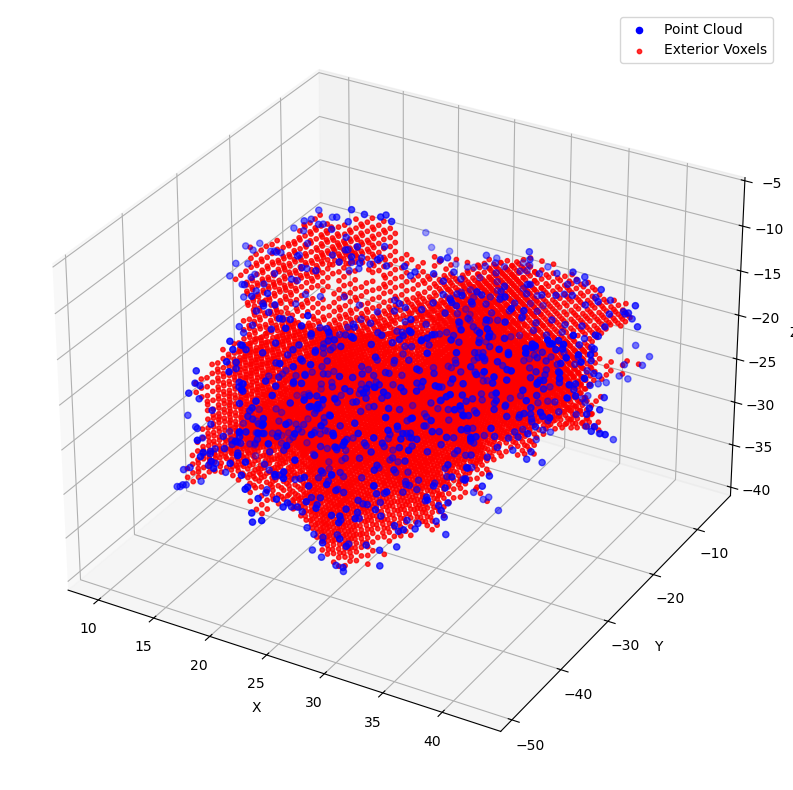

In [ ]:

## ======== Visualization ========
#fig = plt.figure(figsize=(10, 8))
#ax = fig.add_subplot(111, projection='3d')
#
## Plot point cloud in blue
#ax.scatter(point_cloud["x"], point_cloud["y"], point_cloud["z"],
#           s=20, c='blue', label='Point Cloud')
#
## Plot exterior voxels in red
##ax.scatter(exterior_voxels[:, 0], exterior_voxels[:, 1], exterior_voxels[:, 2],
##           s=10, c='red', marker='o', label='Exterior Voxels', alpha = 0.1)
#
## Plot interior voxels in red
#ax.scatter(interior_voxels[:, 0], interior_voxels[:, 1], interior_voxels[:, 2],
#           s=10, c='red', marker='o', label='Exterior Voxels', alpha = 0.8)
#
#ax.set_xlabel('X')
#ax.set_ylabel('Y')
#ax.set_zlabel('Z')
#ax.legend()
#
#plt.tight_layout()
#plt.show()

In [ ]:
for ind, coord in enumerate(voxel_centers[:,:]):

    if not inside[ind]:

        distances, indices = tree.query(coord, k=MAX_NEIGHBOURS)

        probabilities[ind] = model.predict(get_broom(coord, data, indices), verbose = 0)[0][0]



In [ ]:

with open("my_first_carboxamid_map.plk", "wb") as f:
    pickle.dump(probabilities,f)
with open("my_first_map.plk", "rb") as i:
    lp = pickle.load(i)
